In [1]:
import os
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme()


In [2]:
MOVIES_PATH = "tmdb_5000_movies.csv"
CREDITS_PATH = "tmdb_5000_credits.csv"
RATINGS_PATH = "ratings.csv"
LINKS_PATH = "links.csv"

if not os.path.exists(MOVIES_PATH):
    raise FileNotFoundError(
        f"Cannot find {MOVIES_PATH}. Put it in the notebook folder or update MOVIES_PATH."
    )

movies_raw = pd.read_csv(MOVIES_PATH, low_memory=False)

movies_raw = movies_raw.loc[
    :, ~movies_raw.columns.astype(str).str.match(r"^Unnamed:")
].copy()
movies_raw = movies_raw.dropna(axis=1, how="all")

if "id" not in movies_raw.columns or "title" not in movies_raw.columns:
    raise ValueError("The movies CSV must contain 'id' and 'title' columns.")

if "release_date" not in movies_raw.columns:
    movies_raw["release_date"] = pd.NaT

movies_raw["id"] = pd.to_numeric(movies_raw["id"], errors="coerce")
movies_raw["release_date"] = pd.to_datetime(
    movies_raw["release_date"], errors="coerce"
)
movies_raw["release_year"] = movies_raw["release_date"].dt.year.astype("Int64")

if os.path.exists(CREDITS_PATH):
    credits_raw = pd.read_csv(CREDITS_PATH, low_memory=False)
    credits_raw = credits_raw.loc[
        :, ~credits_raw.columns.astype(str).str.match(r"^Unnamed:")
    ].copy()
    credits_raw = credits_raw.dropna(axis=1, how="all")

    if "movie_id" in credits_raw.columns:
        credits_raw["movie_id"] = pd.to_numeric(
            credits_raw["movie_id"], errors="coerce"
        )
        if "id" in movies_raw.columns:
            df = movies_raw.merge(
                credits_raw,
                left_on="id",
                right_on="movie_id",
                how="left",
                suffixes=("", "_credits")
            )
        else:
            df = movies_raw.copy()
    elif "id" in credits_raw.columns:
        credits_raw["id"] = pd.to_numeric(credits_raw["id"], errors="coerce")
        df = movies_raw.merge(
            credits_raw, on="id", how="left", suffixes=("", "_credits")
        )
    else:
        df = movies_raw.copy()
else:
    df = movies_raw.copy()

df = df.loc[:, ~df.columns.astype(str).str.match(r"^Unnamed:")].copy()
df = df.dropna(axis=1, how="all")
df["title"] = df["title"].fillna("").astype(str)
df = df[df["title"].str.strip().ne("")].copy()
df = df.drop_duplicates(subset=["id"] if "id" in df.columns else ["title"])
df = df.reset_index(drop=True)

for col in ["budget", "revenue", "popularity", "vote_average", "vote_count", "runtime"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_year"] = df["release_date"].dt.year.astype("Int64")

print("Dataset shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate titles:", int(df["title"].duplicated().sum()))
print("Valid release dates:", int(df["release_date"].notna().sum()))
print("Missing release dates:", int(df["release_date"].isna().sum()))
display(df.head())


Dataset shape: (4803, 25)
Duplicate rows: 0
Duplicate titles: 3
Valid release dates: 1968
Missing release dates: 2835


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,release_year,movie_id,title_credits,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-10-12,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,2009,19995.0,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",NaT,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,<NA>,285.0,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",NaT,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,<NA>,206647.0,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",NaT,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,<NA>,49026.0,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-03,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,2012,49529.0,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [3]:
missing_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
}).sort_values("Missing Percentage", ascending=False)

display(missing_report)
display(df.describe(include="all").T)


,Data Type,Missing Values,Missing Percentage,Unique Values
homepage,str,3091,64.36,1691
release_year,Int64,2835,59.03,75
release_date,datetime64[us],2835,59.03,1309
tagline,str,844,17.57,3944
overview,str,4,0.08,4799
crew,str,4,0.08,4772
runtime,float64,2,0.04,156
id,int64,0,0.00,4803
budget,int64,0,0.00,436
popularity,float64,0,0.00,4802


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
budget,4803.0,NaN,NaN,NaN,29045039.875286,0.0,790000.0,15000000.0,40000000.0,380000000.0,40722391.25855
genres,4803,1175,"[{""id"": 18, ""name"": ""Drama""}]",370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
homepage,1712,1691,http://www.thehungergames.movie/,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,4803.0,NaN,NaN,NaN,57165.484281,5.0,9014.5,14629.0,58610.5,459488.0,88694.614033
keywords,4803,4222,[],412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_language,4803,37,en,4505,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_title,4803,4801,Batman,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
overview,4799,4799,"In the 22nd century, a paraplegic Marine is di...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,4803.0,NaN,NaN,NaN,21.492301,0.0,4.66807,12.921594,28.313505,875.581305,31.81665
production_companies,4803,3697,[],351,NaN,NaN,NaN,NaN,NaN,NaN,NaN


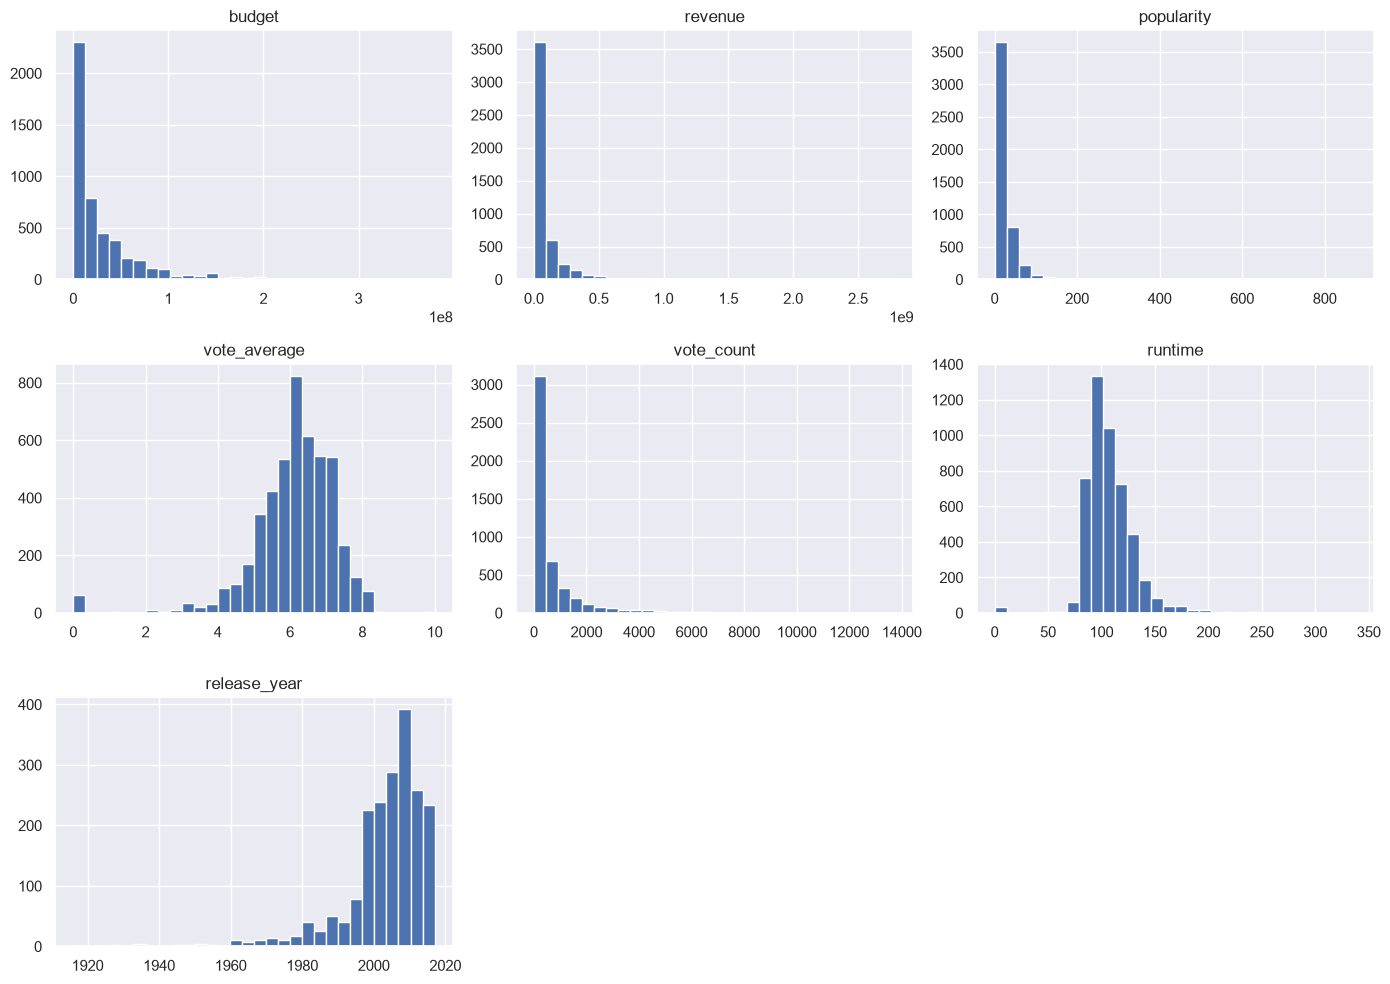

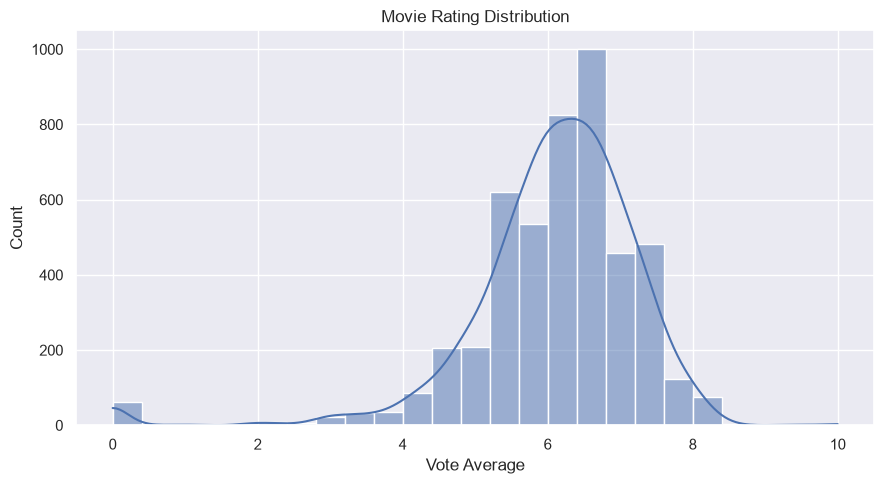

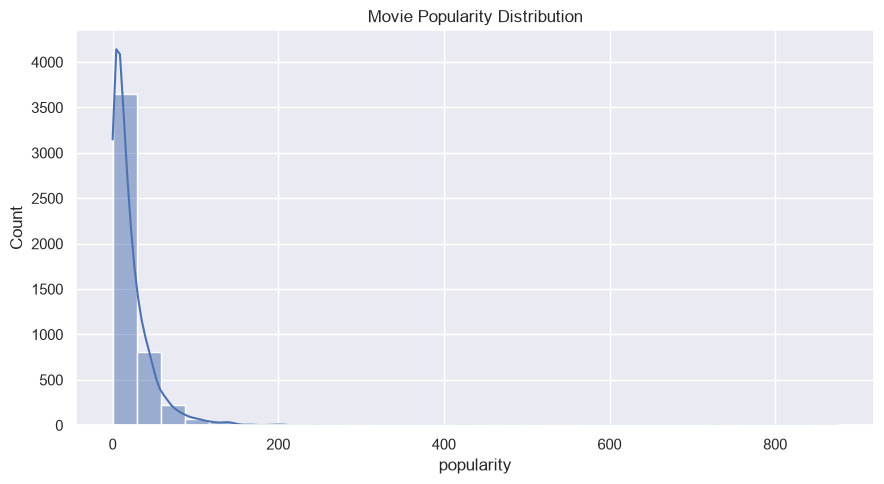

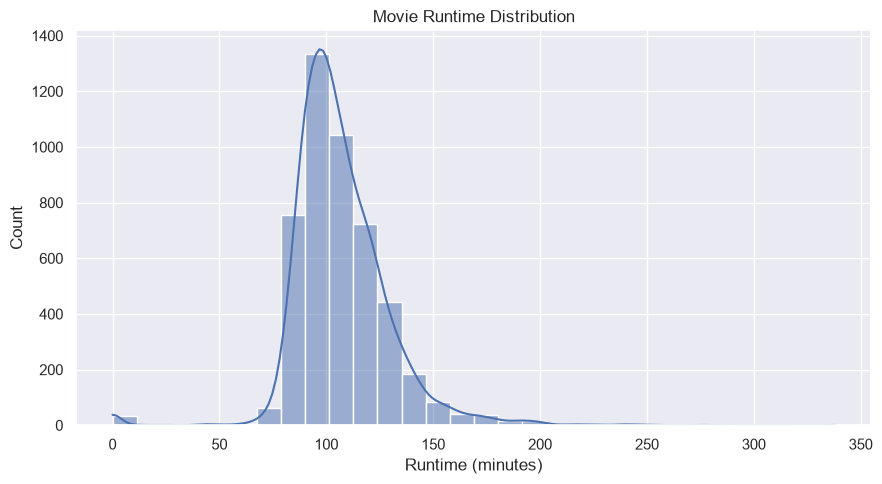

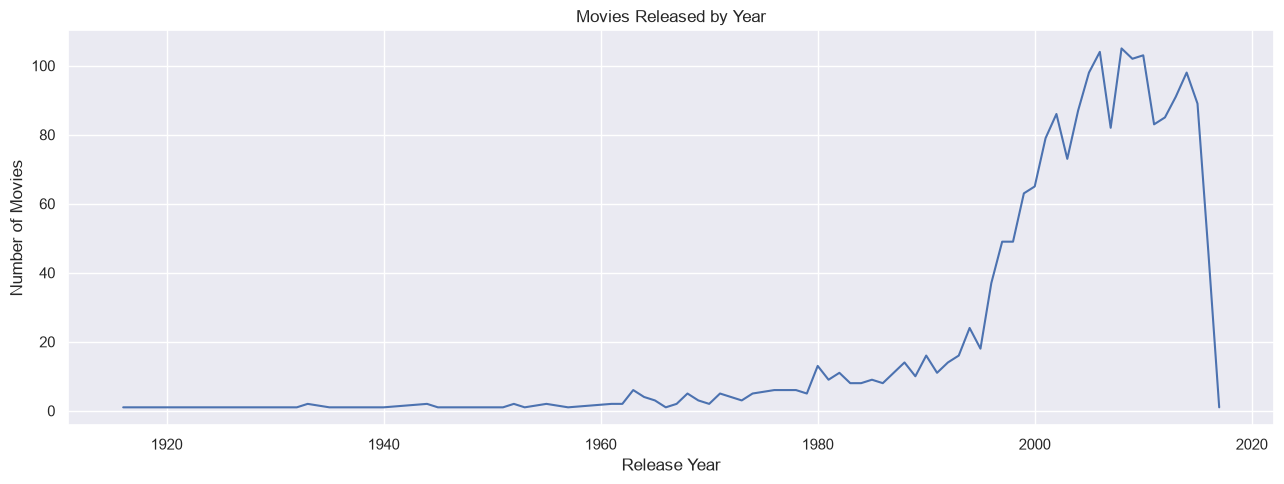

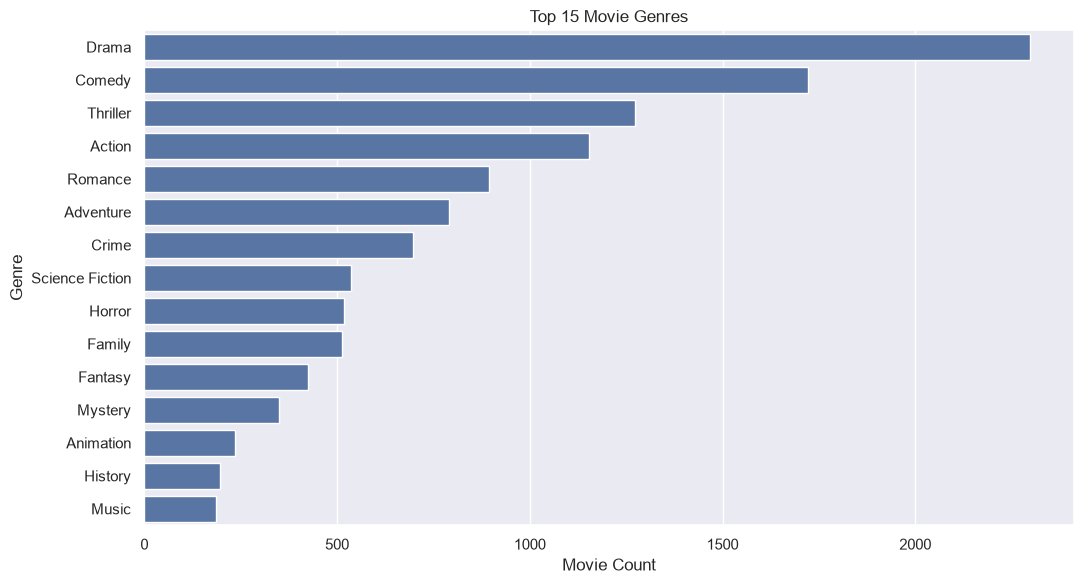

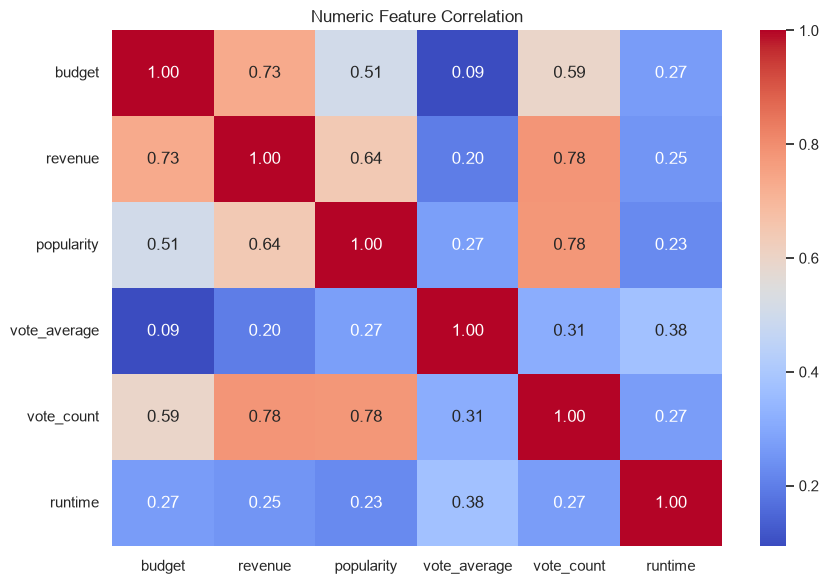

In [4]:
numeric_cols = [
    c for c in ["budget", "revenue", "popularity", "vote_average",
                "vote_count", "runtime", "release_year"]
    if c in df.columns
]

if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=30)
    plt.tight_layout()
    plt.show()

if "vote_average" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["vote_average"].dropna(), bins=25, kde=True)
    plt.title("Movie Rating Distribution")
    plt.xlabel("Vote Average")
    plt.tight_layout()
    plt.show()

if "popularity" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["popularity"].dropna(), bins=30, kde=True)
    plt.title("Movie Popularity Distribution")
    plt.tight_layout()
    plt.show()

if "runtime" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["runtime"].dropna(), bins=30, kde=True)
    plt.title("Movie Runtime Distribution")
    plt.xlabel("Runtime (minutes)")
    plt.tight_layout()
    plt.show()

if "release_year" in df.columns:
    yearly = df["release_year"].dropna().astype(int).value_counts().sort_index()
    if not yearly.empty:
        plt.figure(figsize=(13, 5))
        yearly.plot()
        plt.title("Movies Released by Year")
        plt.xlabel("Release Year")
        plt.ylabel("Number of Movies")
        plt.tight_layout()
        plt.show()

def parse_names(value, key="name"):
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        if isinstance(parsed, list):
            return [
                str(item.get(key, "")).strip()
                for item in parsed
                if isinstance(item, dict) and item.get(key)
            ]
    except (ValueError, SyntaxError, TypeError):
        return []
    return []

if "genres" in df.columns:
    genre_counts = df["genres"].apply(parse_names).explode().value_counts().head(15)
    if not genre_counts.empty:
        plt.figure(figsize=(11, 6))
        sns.barplot(x=genre_counts.values, y=genre_counts.index)
        plt.title("Top 15 Movie Genres")
        plt.xlabel("Movie Count")
        plt.ylabel("Genre")
        plt.tight_layout()
        plt.show()

corr_cols = [
    c for c in ["budget", "revenue", "popularity", "vote_average",
                "vote_count", "runtime"]
    if c in df.columns
]
if len(corr_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Numeric Feature Correlation")
    plt.tight_layout()
    plt.show()


In [5]:
def weighted_rating_table(data):
    out = data.copy()
    if "vote_average" not in out.columns:
        out["vote_average"] = 0.0
    if "vote_count" not in out.columns:
        out["vote_count"] = 0.0

    out["vote_average"] = pd.to_numeric(out["vote_average"], errors="coerce").fillna(0)
    out["vote_count"] = pd.to_numeric(out["vote_count"], errors="coerce").fillna(0)

    valid_votes = out.loc[out["vote_count"] > 0, "vote_count"]
    m = float(valid_votes.quantile(0.70)) if not valid_votes.empty else 0.0
    C = float(out.loc[out["vote_count"] > 0, "vote_average"].mean()) if (out["vote_count"] > 0).any() else 0.0

    denominator = out["vote_count"] + m
    out["weighted_rating"] = np.where(
        denominator > 0,
        (out["vote_count"] / denominator) * out["vote_average"]
        + (m / denominator) * C,
        out["vote_average"]
    )
    return out

popular_movies = weighted_rating_table(df)
sort_cols = [c for c in ["weighted_rating", "popularity"] if c in popular_movies.columns]
display(
    popular_movies.sort_values(sort_cols, ascending=False)
    [["title"] + [c for c in ["release_year", "vote_average", "vote_count", "popularity", "weighted_rating"] if c in popular_movies.columns]]
    .head(20)
)


,title,release_year,vote_average,vote_count,popularity,weighted_rating
1881,The Shawshank Redemption,<NA>,8.5,8205,136.747729,8.344313
3337,The Godfather,<NA>,8.4,5893,143.659698,8.197846
662,Fight Club,<NA>,8.3,9413,146.757391,8.174877
3232,Pulp Fiction,1994,8.3,8428,121.463076,8.161207
65,The Dark Knight,<NA>,8.2,12002,187.322927,8.105277
809,Forrest Gump,1994,8.2,7927,138.133331,8.059946
1818,Schindler's List,<NA>,8.3,4329,104.469351,8.045504
3865,Whiplash,2014,8.3,4254,192.528841,8.041562
96,Inception,<NA>,8.1,13752,167.583710,8.020937
2294,Spirited Away,<NA>,8.3,3840,118.968562,8.017399


In [6]:
def as_text(value):
    if pd.isna(value):
        return ""
    if isinstance(value, str):
        return value
    return str(value)

def make_soup(row):
    parts = []
    for col in ["overview", "tagline"]:
        if col in row.index:
            parts.append(as_text(row[col]))
    for col in ["genres", "keywords", "cast", "crew"]:
        if col in row.index:
            names = parse_names(row[col])
            if col == "crew":
                try:
                    crew = ast.literal_eval(row[col]) if isinstance(row[col], str) else []
                    names = [
                        str(person.get("name", ""))
                        for person in crew
                        if isinstance(person, dict) and person.get("job") == "Director" and person.get("name")
                    ] or names
                except (ValueError, SyntaxError, TypeError):
                    pass
            parts.extend(names)
    return " ".join(parts).lower()

df["soup"] = df.apply(make_soup, axis=1)
df["soup"] = df["soup"].replace("", np.nan).fillna(df["title"].str.lower())

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=30000,
    ngram_range=(1, 2),
    dtype=np.float32
)
tfidf_matrix = tfidf.fit_transform(df["soup"])

title_lookup = {}
for i, title in enumerate(df["title"].astype(str)):
    title_lookup.setdefault(title.casefold().strip(), i)

def find_movie_index(movie_title):
    key = str(movie_title).casefold().strip()
    if key in title_lookup:
        return title_lookup[key]
    matches = df.index[df["title"].str.casefold().str.contains(key, regex=False, na=False)].tolist()
    if matches:
        print("Exact title not found. Using:", df.loc[matches[0], "title"])
        return int(matches[0])
    suggestions = df.loc[
        df["title"].str.casefold().str.contains(key[:max(3, min(len(key), 8))], regex=False, na=False),
        "title"
    ].head(10).tolist() if key else []
    if suggestions:
        print("Possible titles:", suggestions)
    else:
        print("Movie title not found.")
    return None

def recommend_content(movie_title, n=10):
    idx = find_movie_index(movie_title)
    if idx is None:
        return pd.DataFrame()
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()
    scores[idx] = -1
    n = max(1, min(int(n), len(df) - 1))
    candidate_idx = np.argpartition(scores, -n)[-n:]
    candidate_idx = candidate_idx[np.argsort(scores[candidate_idx])[::-1]]
    cols = ["title"] + [c for c in ["release_year", "vote_average", "vote_count", "popularity"] if c in df.columns]
    result = df.iloc[candidate_idx][cols].copy()
    result["content_score"] = scores[candidate_idx]
    return result.reset_index(drop=True)

display(recommend_content("The Dark Knight", 10))


,title,release_year,vote_average,vote_count,popularity,content_score
0,The Dark Knight Rises,<NA>,7.6,9106,112.312950,0.268903
1,Batman Begins,2005,7.5,7359,115.040024,0.231066
2,Batman Returns,<NA>,6.6,1673,59.113174,0.209487
3,Batman Forever,<NA>,5.2,1498,48.205606,0.202818
4,Batman,<NA>,7.0,2096,44.104469,0.176952
5,Batman v Superman: Dawn of Justice,<NA>,5.7,7004,155.790452,0.138279
6,"Batman: The Dark Knight Returns, Part 2",<NA>,7.9,419,25.891466,0.136597
7,Batman & Robin,<NA>,4.2,1418,50.073575,0.127732
8,Superman,<NA>,6.9,1022,48.507081,0.115860
9,Law Abiding Citizen,<NA>,7.2,1486,49.593978,0.114485


In [8]:
display(recommend_content("Superman",5))

,title,release_year,vote_average,vote_count,popularity,content_score
0,Superman II,1980,6.5,629,30.515175,0.368068
1,Superman IV: The Quest for Peace,<NA>,4.1,318,17.062117,0.274163
2,Superman Returns,<NA>,5.4,1400,57.925623,0.251205
3,Superman III,<NA>,5.3,490,22.164202,0.250352
4,Man of Steel,2013,6.5,6359,99.398009,0.165159


In [12]:
collaborative_available = (
    os.path.exists(RATINGS_PATH)
    and os.path.exists(LINKS_PATH)
)

ratings = None
links = None
svd_model = None
user_item = None
movie_factors = None
tmdb_to_movieidx = {}

if collaborative_available:
    ratings = pd.read_csv(RATINGS_PATH)
    links = pd.read_csv(LINKS_PATH)

    required_ratings = {"userId", "movieId", "rating"}
    required_links = {"movieId", "tmdbId"}

    if not required_ratings.issubset(ratings.columns) or not required_links.issubset(links.columns):
        print("Collaborative filtering unavailable: ratings.csv or links.csv has unexpected columns.")
        collaborative_available = False
    else:
        links["tmdbId"] = pd.to_numeric(links["tmdbId"], errors="coerce")
        df["id"] = pd.to_numeric(df["id"], errors="coerce")
        tmdb_lookup = pd.Series(df.index.values, index=df["id"]).to_dict()
        links["df_index"] = links["tmdbId"].map(tmdb_lookup)
        links = links.dropna(subset=["df_index"]).copy()
        links["df_index"] = links["df_index"].astype(int)
        ratings = ratings.merge(links[["movieId", "df_index"]], on="movieId", how="inner")
        ratings = ratings.dropna(subset=["rating", "df_index"])
        ratings["df_index"] = ratings["df_index"].astype(int)

        if ratings.empty or ratings["userId"].nunique() < 2 or ratings["df_index"].nunique() < 2:
            print("Collaborative filtering unavailable: not enough matched ratings.")
            collaborative_available = False
        else:
            user_item = ratings.pivot_table(
                index="userId", columns="df_index", values="rating", aggfunc="mean"
            ).fillna(0)
            n_components = max(1, min(50, min(user_item.shape) - 1))
            if n_components < 1:
                collaborative_available = False
                print("Collaborative filtering unavailable: ratings matrix is too small.")
            else:
                svd_model = TruncatedSVD(n_components=n_components, random_state=42)
                movie_factors = svd_model.fit_transform(user_item.T)
                tmdb_to_movieidx = {int(idx): j for j, idx in enumerate(user_item.columns)}
                print("Collaborative filtering enabled.")
else:
    print("Collaborative filtering skipped: add MovieLens ratings.csv and links.csv to enable it.")

def recommend_collaborative(movie_title, n=10):
    if not collaborative_available or movie_factors is None:
        print("Collaborative filtering is unavailable. Add valid MovieLens ratings.csv and links.csv.")
        return pd.DataFrame()
    idx = find_movie_index(movie_title)
    if idx is None or idx not in tmdb_to_movieidx:
        print("This movie has no matched MovieLens ratings.")
        return pd.DataFrame()
    factor_idx = tmdb_to_movieidx[idx]
    sims = cosine_similarity(movie_factors[factor_idx].reshape(1, -1), movie_factors).ravel()
    sims[factor_idx] = -1
    ranked = np.argsort(sims)[::-1]
    result_rows = []
    for j in ranked:
        df_idx = list(tmdb_to_movieidx.keys())[list(tmdb_to_movieidx.values()).index(j)]
        if df_idx == idx:
            continue
        result_rows.append((df_idx, sims[j]))
        if len(result_rows) >= int(n):
            break
    indices = [x[0] for x in result_rows]
    scores = [x[1] for x in result_rows]
    result = df.iloc[indices][["title"] + [c for c in ["release_year", "vote_average", "vote_count", "popularity"] if c in df.columns]].copy()
    result["collaborative_score"] = scores
    return result.reset_index(drop=True)

def recommend_hybrid(movie_title, n=10, content_weight=0.7):
    idx = find_movie_index(movie_title)
    if idx is None:
        return pd.DataFrame()

    content_scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()
    content_scores[idx] = 0
    content_norm = normalize_array(content_scores)

    hybrid_scores = content_weight * content_norm
    method = "Content-only fallback (ratings unavailable)"

    if collaborative_available and movie_factors is not None and idx in tmdb_to_movieidx:
        factor_idx = tmdb_to_movieidx[idx]
        collab = cosine_similarity(movie_factors[factor_idx].reshape(1, -1), movie_factors).ravel()
        collab_full = np.zeros(len(df), dtype=float)
        for movie_df_idx, j in tmdb_to_movieidx.items():
            collab_full[movie_df_idx] = collab[j]
        collab_full[idx] = 0
        collab_norm = normalize_array(collab_full)
        hybrid_scores = content_weight * content_norm + (1 - content_weight) * collab_norm
        method = "Hybrid: content + collaborative"

    hybrid_scores[idx] = -1
    n = max(1, min(int(n), len(df) - 1))
    candidate_idx = np.argpartition(hybrid_scores, -n)[-n:]
    candidate_idx = candidate_idx[np.argsort(hybrid_scores[candidate_idx])[::-1]]
    cols = ["title"] + [c for c in ["release_year", "vote_average", "vote_count", "popularity"] if c in df.columns]
    result = df.iloc[candidate_idx][cols].copy()
    result["hybrid_score"] = hybrid_scores[candidate_idx]
    result["recommendation_method"] = method
    return result.reset_index(drop=True)

def normalize_array(values):
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    if not finite.any():
        return np.zeros_like(values)
    low = values[finite].min()
    high = values[finite].max()
    result = np.zeros_like(values)
    if high > low:
        result[finite] = (values[finite] - low) / (high - low)
    else:
        result[finite] = 0
    return result

display(recommend_hybrid("The Dark Knight", 10))


Collaborative filtering skipped: add MovieLens ratings.csv and links.csv to enable it.


,title,release_year,vote_average,vote_count,popularity,hybrid_score,recommendation_method
0,The Dark Knight Rises,<NA>,7.6,9106,112.312950,0.700000,Content-only fallback (ratings unavailable)
1,Batman Begins,2005,7.5,7359,115.040024,0.601503,Content-only fallback (ratings unavailable)
2,Batman Returns,<NA>,6.6,1673,59.113174,0.545330,Content-only fallback (ratings unavailable)
3,Batman Forever,<NA>,5.2,1498,48.205606,0.527969,Content-only fallback (ratings unavailable)
4,Batman,<NA>,7.0,2096,44.104469,0.460635,Content-only fallback (ratings unavailable)
5,Batman v Superman: Dawn of Justice,<NA>,5.7,7004,155.790452,0.359964,Content-only fallback (ratings unavailable)
6,"Batman: The Dark Knight Returns, Part 2",<NA>,7.9,419,25.891466,0.355584,Content-only fallback (ratings unavailable)
7,Batman & Robin,<NA>,4.2,1418,50.073575,0.332508,Content-only fallback (ratings unavailable)
8,Superman,<NA>,6.9,1022,48.507081,0.301602,Content-only fallback (ratings unavailable)
9,Law Abiding Citizen,<NA>,7.2,1486,49.593978,0.298024,Content-only fallback (ratings unavailable)


In [13]:
example_movies = [
    "The Dark Knight",
    "Inception",
    "Toy Story",
    "Titanic",
    "Avatar"
]

for movie_name in example_movies:
    print(f"\nContent-based recommendations for: {movie_name}")
    display(recommend_content(movie_name, 5))

    print(f"Hybrid recommendations for: {movie_name}")
    display(recommend_hybrid(movie_name, 5))



Content-based recommendations for: The Dark Knight


,title,release_year,vote_average,vote_count,popularity,content_score
0,The Dark Knight Rises,<NA>,7.6,9106,112.312950,0.268903
1,Batman Begins,2005,7.5,7359,115.040024,0.231066
2,Batman Returns,<NA>,6.6,1673,59.113174,0.209487
3,Batman Forever,<NA>,5.2,1498,48.205606,0.202818
4,Batman,<NA>,7.0,2096,44.104469,0.176952


Hybrid recommendations for: The Dark Knight


,title,release_year,vote_average,vote_count,popularity,hybrid_score,recommendation_method
0,The Dark Knight Rises,<NA>,7.6,9106,112.312950,0.700000,Content-only fallback (ratings unavailable)
1,Batman Begins,2005,7.5,7359,115.040024,0.601503,Content-only fallback (ratings unavailable)
2,Batman Returns,<NA>,6.6,1673,59.113174,0.545330,Content-only fallback (ratings unavailable)
3,Batman Forever,<NA>,5.2,1498,48.205606,0.527969,Content-only fallback (ratings unavailable)
4,Batman,<NA>,7.0,2096,44.104469,0.460635,Content-only fallback (ratings unavailable)



Content-based recommendations for: Inception


...

,title,release_year,vote_average,vote_count,popularity,hybrid_score,recommendation_method
0,Raise the Titanic,1980,5.2,21,1.630541,0.700000,Content-only fallback (ratings unavailable)
1,The Bounty,1984,6.5,108,7.436491,0.631868,Content-only fallback (ratings unavailable)
2,Return of the Jedi,<NA>,7.9,4665,46.509071,0.524360,Content-only fallback (ratings unavailable)
3,The Notebook,<NA>,7.7,3067,55.109138,0.464483,Content-only fallback (ratings unavailable)
4,Real Steel,<NA>,6.6,2692,37.195046,0.449675,Content-only fallback (ratings unavailable)



Content-based recommendations for: Avatar


,title,release_year,vote_average,vote_count,popularity,content_score
0,Aliens,<NA>,7.7,3220,67.660940,0.169943
1,Alien,<NA>,7.9,4470,94.184658,0.134053
2,Alien³,<NA>,6.2,1633,45.856409,0.130350
3,Star Trek Into Darkness,2013,7.4,4418,78.291018,0.126495
4,Moonraker,<NA>,5.9,541,29.887404,0.126331


Hybrid recommendations for: Avatar


,title,release_year,vote_average,vote_count,popularity,hybrid_score,recommendation_method
0,Aliens,<NA>,7.7,3220,67.660940,0.700000,Content-only fallback (ratings unavailable)
1,Alien,<NA>,7.9,4470,94.184658,0.552168,Content-only fallback (ratings unavailable)
2,Alien³,<NA>,6.2,1633,45.856409,0.536915,Content-only fallback (ratings unavailable)
3,Star Trek Into Darkness,2013,7.4,4418,78.291018,0.521035,Content-only fallback (ratings unavailable)
4,Moonraker,<NA>,5.9,541,29.887404,0.520362,Content-only fallback (ratings unavailable)
